# Movie Recommendation and User Behavior Analytics

**Project workflow:** SQLite MovieLens data → PySpark DataFrames → exploratory data analysis → ALS recommendation model → RMSE evaluation → user-specific recommendations.

## Before running

1. Keep `movielens-small.db` in the same project folder as this notebook.
2. Open this folder in VS Code and select the Python environment where PySpark is installed.
3. Run the notebook from top to bottom, one cell at a time.
4. This notebook uses a local Spark session. The MovieLens sample contains approximately 100,000 ratings, so this is a learning/demo project rather than a large production-scale cluster.

## 1. Environment and imports

In [1]:
import os
import sys
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# Ensure Spark workers use the same Python interpreter as this notebook.
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: c:\Users\Lenovo\.conda\envs\movie-spark\python.exe
Python version: 3.11.18 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 18:13:29) [MSC v.1942 64 bit (AMD64)]


In [2]:
import pyspark
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, count, avg, desc, explode
from pyspark.sql.types import (
    StructType, StructField,
    IntegerType, StringType, FloatType, LongType
)
from pyspark.ml.recommendation import ALS
from pyspark.ml.evaluation import RegressionEvaluator

print("PySpark version:", pyspark.__version__)

PySpark version: 3.5.6


In [3]:
# Create one SparkSession for the entire notebook.
spark = (
    SparkSession.builder
    .appName("MovieRecommendationSystem")
    .master("local[2]")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")
print("Spark version:", spark.version)
print("Spark session created successfully!")

Spark version: 3.5.6
Spark session created successfully!


## 2. Connect to the SQLite database

In [4]:
# The database must be in the same folder as this notebook.
DB_PATH = os.path.abspath("movielens-small.db")

if not os.path.isfile(DB_PATH):
    raise FileNotFoundError(
        f"Database not found: {DB_PATH}\n"
        "Place movielens-small.db beside this notebook or update DB_PATH."
    )

con = sqlite3.connect(DB_PATH)
cursor = con.cursor()

cursor.execute(
    "SELECT name FROM sqlite_master WHERE type='table' ORDER BY name"
)
table_names = [row[0] for row in cursor.fetchall()]

print("Connected to:", DB_PATH)
print("Available tables:", table_names)

required_tables = {"movies", "ratings", "links", "tags"}
missing_tables = required_tables.difference(table_names)
if missing_tables:
    raise RuntimeError(f"Missing required database tables: {sorted(missing_tables)}")

Connected to: d:\movie_recommendation_system-main\movielens-small.db
Available tables: ['links', 'movie_ratings', 'movies', 'movies_2', 'ratings', 'tags']


In [5]:
# Inspect row counts and sample records from the source database.
for table_name in ["movies", "ratings", "links", "tags"]:
    cursor.execute(f'SELECT COUNT(*) FROM "{table_name}"')
    print(f"{table_name}: {cursor.fetchone()[0]:,} records")

print("\nSample movies:")
cursor.execute("SELECT * FROM movies LIMIT 5")
for row in cursor.fetchall():
    print(row)

print("\nSample ratings:")
cursor.execute("SELECT * FROM ratings LIMIT 5")
for row in cursor.fetchall():
    print(row)

movies: 8,570 records
ratings: 100,023 records
links: 8,570 records
tags: 2,488 records

Sample movies:
(1, 'Toy Story', 1995, 'Adventure|Animation|Children|Comedy|Fantasy')
(2, 'Jumanji', 1995, 'Adventure|Children|Fantasy')
(3, 'Grumpier Old Men', 1995, 'Comedy|Romance')
(4, 'Waiting to Exhale', 1995, 'Comedy|Drama|Romance')
(5, 'Father of the Bride Part II', 1995, 'Comedy')

Sample ratings:
(1, 6, 2.0, 980730861)
(1, 22, 3.0, 980731380)
(1, 32, 2.0, 980731926)
(1, 50, 5.0, 980732037)
(1, 110, 4.0, 980730408)


## 3. Load SQLite tables into Spark DataFrames

In [6]:
# Explicit schemas avoid inconsistent type inference from SQLite values.
movies_schema = StructType([
    StructField("movieId", IntegerType(), True),
    StructField("title", StringType(), True),
    StructField("year", IntegerType(), True),
    StructField("genres", StringType(), True)
])

ratings_schema = StructType([
    StructField("userId", IntegerType(), True),
    StructField("movieId", IntegerType(), True),
    StructField("rating", FloatType(), True),
    StructField("timestamp", LongType(), True)
])

links_schema = StructType([
    StructField("movieId", IntegerType(), True),
    StructField("imdbId", StringType(), True),
    StructField("tmdbId", StringType(), True)
])

tags_schema = StructType([
    StructField("userId", IntegerType(), True),
    StructField("movieId", IntegerType(), True),
    StructField("tag", StringType(), True),
    StructField("timestamp", LongType(), True)
])

movies_data = cursor.execute(
    "SELECT movieId, title, year, genres FROM movies"
).fetchall()
ratings_data = cursor.execute(
    "SELECT userId, movieId, rating, timestamp FROM ratings"
).fetchall()
links_data = cursor.execute(
    "SELECT movieId, imdbId, tmdbId FROM links"
).fetchall()
tags_data = cursor.execute(
    "SELECT userId, movieId, tag, timestamp FROM tags"
).fetchall()

movies_spark = spark.createDataFrame(movies_data, schema=movies_schema)
ratings_spark = spark.createDataFrame(ratings_data, schema=ratings_schema)
links_spark = spark.createDataFrame(links_data, schema=links_schema)
tags_spark = spark.createDataFrame(tags_data, schema=tags_schema)

print("All four tables loaded into Spark successfully.")

All four tables loaded into Spark successfully.


In [7]:
print("Movies:", movies_spark.count())
print("Ratings:", ratings_spark.count())
print("Links:", links_spark.count())
print("Tags:", tags_spark.count())

print("\nRatings schema:")
ratings_spark.printSchema()
print("\nMovie sample:")
movies_spark.show(5, truncate=False)

Movies: 8570
Ratings: 100023
Links: 8570
Tags: 2488

Ratings schema:
root
 |-- userId: integer (nullable = true)
 |-- movieId: integer (nullable = true)
 |-- rating: float (nullable = true)
 |-- timestamp: long (nullable = true)


Movie sample:
+-------+---------------------------+----+-------------------------------------------+
|movieId|title                      |year|genres                                     |
+-------+---------------------------+----+-------------------------------------------+
|1      |Toy Story                  |1995|Adventure|Animation|Children|Comedy|Fantasy|
|2      |Jumanji                    |1995|Adventure|Children|Fantasy                 |
|3      |Grumpier Old Men           |1995|Comedy|Romance                             |
|4      |Waiting to Exhale          |1995|Comedy|Drama|Romance                       |
|5      |Father of the Bride Part II|1995|Comedy                                     |
+-------+---------------------------+----+-----------------

## 4. Exploratory Data Analysis

In [8]:
# Most popular movies by number of ratings.
movie_popularity = (
    ratings_spark.groupBy("movieId")
    .agg(count("rating").alias("rating_count"))
    .join(movies_spark, on="movieId", how="inner")
    .select("movieId", "title", "rating_count")
    .orderBy(desc("rating_count"))
)

movie_popularity.show(10, truncate=False)

+-------+----------------------------------+------------+
|movieId|title                             |rating_count|
+-------+----------------------------------+------------+
|593    |Silence of the Lambs, The         |337         |
|318    |Shawshank Redemption, The         |328         |
|296    |Pulp Fiction                      |327         |
|480    |Jurassic Park                     |324         |
|356    |Forrest Gump                      |318         |
|260    |Star Wars: Episode IV - A New Hope|306         |
|110    |Braveheart                        |292         |
|589    |Terminator 2: Judgment Day        |278         |
|2571   |Matrix, The                       |265         |
|457    |Fugitive, The                     |250         |
+-------+----------------------------------+------------+
only showing top 10 rows



In [9]:
# Highest average-rated movies with at least 50 ratings.
movie_avg_ratings = (
    ratings_spark.groupBy("movieId")
    .agg(
        count("rating").alias("rating_count"),
        avg("rating").alias("average_rating")
    )
    .filter(col("rating_count") >= 50)
    .join(movies_spark, on="movieId", how="inner")
    .select("movieId", "title", "average_rating", "rating_count")
    .orderBy(desc("average_rating"))
)

movie_avg_ratings.show(10, truncate=False)

+-------+------------------------------------+------------------+------------+
|movieId|title                               |average_rating    |rating_count|
+-------+------------------------------------+------------------+------------+
|318    |Shawshank Redemption, The           |4.442073170731708 |328         |
|2019   |Seven Samurai (Shichinin no samurai)|4.408333333333333 |60          |
|50     |Usual Suspects, The                 |4.368200836820083 |239         |
|858    |Godfather, The                      |4.334134615384615 |208         |
|527    |Schindler's List                    |4.3112033195020745|241         |
|1204   |Lawrence of Arabia                  |4.287037037037037 |54          |
|79132  |Inception                           |4.285714285714286 |63          |
|923    |Citizen Kane                        |4.2771739130434785|92          |
|912    |Casablanca                          |4.25968992248062  |129         |
|6016   |City of God (Cidade de Deus)        |4.2583

In [10]:
# Most active users.
active_users = (
    ratings_spark.groupBy("userId")
    .agg(count("rating").alias("total_ratings"))
    .orderBy(desc("total_ratings"))
)
active_users.show(10)

+------+-------------+
|userId|total_ratings|
+------+-------------+
|   516|         2268|
|   384|         1412|
|   187|         1338|
|    31|         1283|
|   377|         1241|
|   484|         1240|
|   302|         1097|
|   176|         1065|
|   364|         1001|
|   614|          975|
+------+-------------+
only showing top 10 rows



In [11]:
# Distribution of ratings.
rating_distribution = (
    ratings_spark.groupBy("rating")
    .count()
    .orderBy("rating")
)
rating_distribution.show()

+------+-----+
|rating|count|
+------+-----+
|   0.5| 1284|
|   1.0| 3857|
|   1.5| 1389|
|   2.0| 7255|
|   2.5| 4354|
|   3.0|22803|
|   3.5|11184|
|   4.0|26430|
|   4.5| 6738|
|   5.0|14729|
+------+-----+



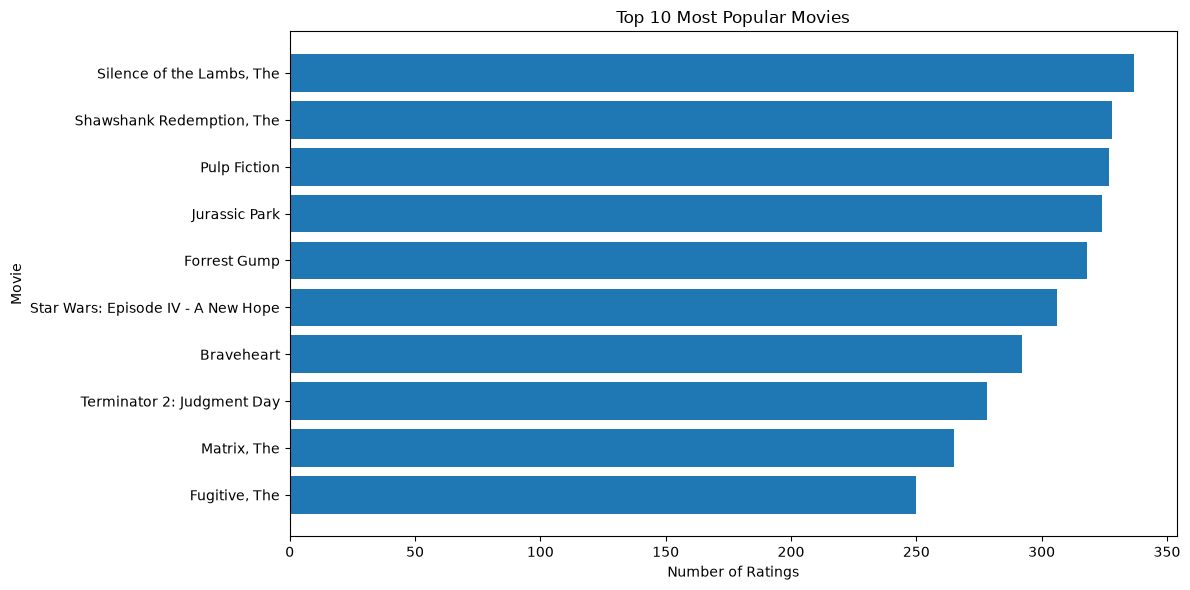

In [12]:
# Plot the 10 most popular movies.
popularity_pd = movie_popularity.limit(10).toPandas()

plt.figure(figsize=(12, 6))
plt.barh(
    popularity_pd["title"][::-1],
    popularity_pd["rating_count"][::-1]
)
plt.xlabel("Number of Ratings")
plt.ylabel("Movie")
plt.title("Top 10 Most Popular Movies")
plt.tight_layout()
plt.show()

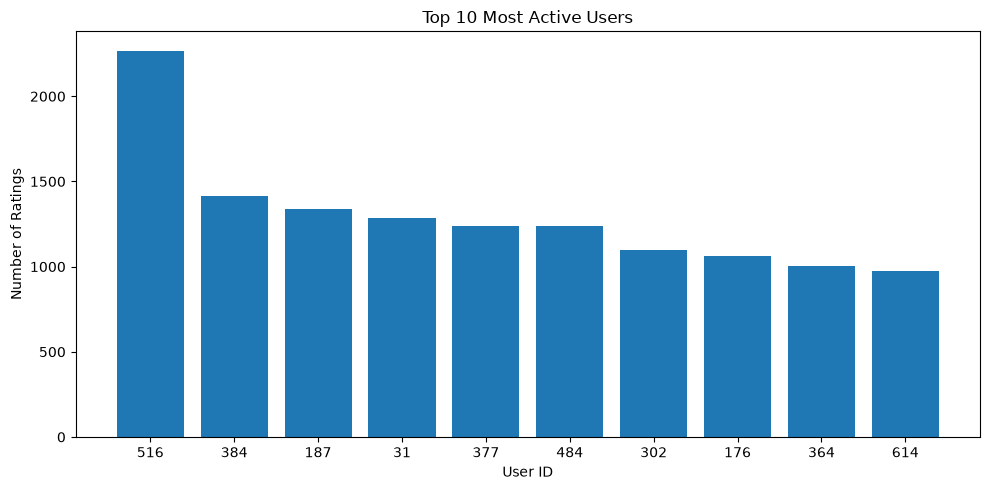

In [13]:
# Plot the 10 most active users.
active_users_pd = active_users.limit(10).toPandas()

plt.figure(figsize=(10, 5))
plt.bar(
    active_users_pd["userId"].astype(str),
    active_users_pd["total_ratings"]
)
plt.xlabel("User ID")
plt.ylabel("Number of Ratings")
plt.title("Top 10 Most Active Users")
plt.tight_layout()
plt.show()

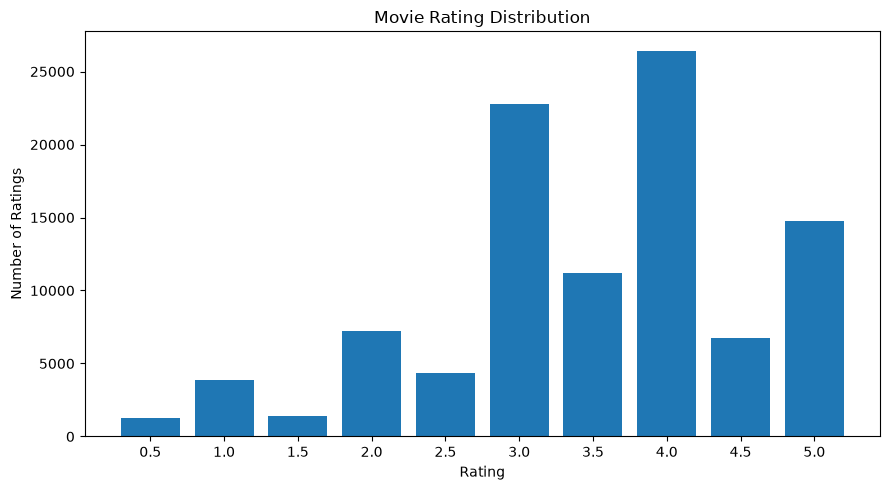

In [14]:
# Plot rating distribution.
rating_distribution_pd = rating_distribution.toPandas()

plt.figure(figsize=(9, 5))
plt.bar(
    rating_distribution_pd["rating"].astype(str),
    rating_distribution_pd["count"]
)
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.title("Movie Rating Distribution")
plt.tight_layout()
plt.show()

## 5. SQL-based analysis (original project task)

In [15]:
def read_dataframe(limit=10):
    query = '''
        SELECT r.userId, r.movieId, m.genres, r.rating
        FROM ratings AS r
        JOIN movies AS m ON r.movieId = m.movieId
        LIMIT ?
    '''
    result = cursor.execute(query, (limit,)).fetchall()
    print("USER_ID | MOVIE_ID | GENRE | RATING")
    for row in result:
        print(row)


def list_top5count_movies():
    query = '''
        SELECT m.title, COUNT(r.rating) AS rating_count
        FROM movies AS m
        JOIN ratings AS r ON m.movieId = r.movieId
        GROUP BY m.movieId, m.title
        ORDER BY rating_count DESC
        LIMIT 5
    '''
    for row in cursor.execute(query).fetchall():
        print(row)


def list_top5rated_genres():
    # The source dataset stores genre combinations in one string per movie.
    query = '''
        SELECT m.genres, SUM(r.rating) AS sum_rating
        FROM movies AS m
        JOIN ratings AS r ON m.movieId = r.movieId
        GROUP BY m.genres
        ORDER BY sum_rating DESC
        LIMIT 5
    '''
    for row in cursor.execute(query).fetchall():
        print(row)

print("Sample user/movie/genre/rating rows:")
read_dataframe(10)
print("\nTop 5 movies by rating count:")
list_top5count_movies()
print("\nTop 5 genre combinations by sum of ratings:")
list_top5rated_genres()

Sample user/movie/genre/rating rows:
USER_ID | MOVIE_ID | GENRE | RATING
(1, 6, 'Action|Crime|Thriller', 2.0)
(1, 22, 'Crime|Drama|Horror|Mystery|Thriller', 3.0)
(1, 32, 'Mystery|Sci-Fi|Thriller', 2.0)
(1, 50, 'Crime|Mystery|Thriller', 5.0)
(1, 110, 'Action|Drama|War', 4.0)
(1, 164, 'Crime|Film-Noir|Mystery|Thriller', 3.0)
(1, 198, 'Action|Crime|Drama|Mystery|Sci-Fi|Thriller', 3.0)
(1, 260, 'Action|Adventure|Sci-Fi', 5.0)
(1, 296, 'Comedy|Crime|Drama|Thriller', 4.0)
(1, 303, 'Action|Thriller|Western', 3.0)

Top 5 movies by rating count:
('Silence of the Lambs, The', 337)
('Shawshank Redemption, The', 328)
('Pulp Fiction', 327)
('Jurassic Park', 324)
('Forrest Gump', 318)

Top 5 genre combinations by sum of ratings:
('Drama', 25650.0)
('Comedy', 20529.5)
('Comedy|Romance', 12930.5)
('Drama|Romance', 11295.5)
('Comedy|Drama', 10709.5)


## 6. Prepare data for ALS recommendation

In [16]:
# Use consistent column names throughout the recommendation section.
ratings = ratings_spark.select(
    col("userId").alias("User_Id"),
    col("movieId").alias("Movie_Id"),
    col("rating").cast("double").alias("Rating")
)

movies = movies_spark.select(
    col("movieId").alias("Movie_Id"),
    col("genres").alias("Genres"),
    col("title").alias("Title")
)

print("Ratings:")
ratings.show(5)
print("Movies:")
movies.show(5, truncate=False)
print("Total ratings:", ratings.count())
print("Total movies:", movies.count())

Ratings:
+-------+--------+------+
|User_Id|Movie_Id|Rating|
+-------+--------+------+
|      1|       6|   2.0|
|      1|      22|   3.0|
|      1|      32|   2.0|
|      1|      50|   5.0|
|      1|     110|   4.0|
+-------+--------+------+
only showing top 5 rows

Movies:
+--------+-------------------------------------------+---------------------------+
|Movie_Id|Genres                                     |Title                      |
+--------+-------------------------------------------+---------------------------+
|1       |Adventure|Animation|Children|Comedy|Fantasy|Toy Story                  |
|2       |Adventure|Children|Fantasy                 |Jumanji                    |
|3       |Comedy|Romance                             |Grumpier Old Men           |
|4       |Comedy|Drama|Romance                       |Waiting to Exhale          |
|5       |Comedy                                     |Father of the Bride Part II|
+--------+-------------------------------------------+------

In [17]:
# Calculate rating sparsity.
num_ratings = ratings.count()
num_users = ratings.select("User_Id").distinct().count()
num_movies = ratings.select("Movie_Id").distinct().count()

total_possible_ratings = num_users * num_movies
sparsity = (1 - num_ratings / total_possible_ratings) * 100

print(f"Unique users: {num_users:,}")
print(f"Unique movies: {num_movies:,}")
print(f"Observed ratings: {num_ratings:,}")
print(f"Ratings matrix sparsity: {sparsity:.2f}%")

Unique users: 706
Unique movies: 8,552
Observed ratings: 100,023
Ratings matrix sparsity: 98.34%


In [18]:
# Rating activity by user and by movie.
userId_ratings = (
    ratings.groupBy("User_Id")
    .count()
    .orderBy(col("count").desc())
)
movieId_ratings = (
    ratings.groupBy("Movie_Id")
    .count()
    .orderBy(col("count").desc())
)

print("Users with the most ratings:")
userId_ratings.show(5)
print("Movies with the most ratings:")
movieId_ratings.show(5)

Users with the most ratings:
+-------+-----+
|User_Id|count|
+-------+-----+
|    516| 2268|
|    384| 1412|
|    187| 1338|
|     31| 1283|
|    377| 1241|
+-------+-----+
only showing top 5 rows

Movies with the most ratings:
+--------+-----+
|Movie_Id|count|
+--------+-----+
|     593|  337|
|     318|  328|
|     296|  327|
|     480|  324|
|     356|  318|
+--------+-----+
only showing top 5 rows



## 7. Train and evaluate the ALS model

This notebook uses one reproducible ALS configuration as the baseline model. The original notebook's repeated tuning cells were removed so the end-to-end workflow can run without repeatedly launching multiple Spark training jobs. Hyperparameter tuning can be added later as a separate optional experiment after this baseline runs successfully.

In [19]:
# Split ratings into training and test sets.
train, test = ratings.randomSplit([0.7, 0.3], seed=42)

print("Training records:", train.count())
print("Testing records:", test.count())
train.printSchema()

Training records: 70189
Testing records: 29834
root
 |-- User_Id: integer (nullable = true)
 |-- Movie_Id: integer (nullable = true)
 |-- Rating: double (nullable = true)



In [20]:
# Train the ALS collaborative-filtering model.
als = ALS(
    userCol="User_Id",
    itemCol="Movie_Id",
    ratingCol="Rating",
    rank=10,
    maxIter=10,
    regParam=0.1,
    coldStartStrategy="drop",
    nonnegative=True,
    seed=42
)

als_model = als.fit(train)
print("ALS model trained successfully!")

ALS model trained successfully!


In [21]:
# Evaluate predictions using RMSE.
evaluator = RegressionEvaluator(
    metricName="rmse",
    labelCol="Rating",
    predictionCol="prediction"
)

test_predictions = als_model.transform(test)
test_predictions.show(10)

rmse = evaluator.evaluate(test_predictions)
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

+-------+--------+------+----------+
|User_Id|Movie_Id|Rating|prediction|
+-------+--------+------+----------+
|     31|    1580|   3.0| 2.0072007|
|     31|    3175|   3.0| 3.1246428|
|    193|     471|   3.5| 4.2231154|
|    332|    1645|   3.0| 3.2536168|
|    159|     471|   4.0| 3.7796197|
|    103|    1959|   5.0| 3.6519651|
|    236|    1580|   3.5| 3.6202383|
|    285|     471|   4.5| 3.7884388|
|    330|    1591|   4.0| 2.7052197|
|    330|    1645|   4.5|  3.929173|
+-------+--------+------+----------+
only showing top 10 rows

Root Mean Squared Error (RMSE): 0.9546


In [23]:
# # Keep a common model variable for the recommendation section.
# best_model = als_model

# print("Model parameters")
# print("Rank:", best_model.rank)
# print("Max iterations:", best_model.getMaxIter())
# print("Regularization parameter:", best_model.getRegParam())

# Keep a common model variable for the recommendation section
best_model = als_model

print("Model parameters")
print("Rank:", best_model.rank)
print("Max iterations:", als.getMaxIter())
print("Regularization parameter:", als.getRegParam())

print("ALS model ready for recommendations!")

Model parameters
Rank: 10
Max iterations: 10
Regularization parameter: 0.1
ALS model ready for recommendations!


## 8. Generate movie recommendations

In [24]:
# Generate 10 recommendations for each user.
user_recommendations = best_model.recommendForAllUsers(10)
user_recommendations.show(5, truncate=False)

+-------+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|User_Id|recommendations                                                                                                                                                                              |
+-------+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|1      |[{7070, 4.6609197}, {4710, 4.501602}, {7341, 4.4751697}, {8491, 4.432459}, {6140, 4.335397}, {2443, 4.2514653}, {3801, 4.198255}, {4337, 4.181658}, {3959, 4.175081}, {3681, 4.16947}]       |
|2      |[{5450, 5.903109}, {8477, 5.8886085}, {2732, 5.8335915}, {2202, 5.8199883}, {745, 5.7583857}, {31193, 5.6823416}, {37830, 5.6479897}, {2612, 5.640269}, {3840, 5.6139927}, {68954, 5.601506}]|


In [25]:
# Expand the recommendations array into one row per recommended movie.
recommendations = (
    user_recommendations
    .withColumn("recommendation", explode("recommendations"))
    .select(
        "User_Id",
        col("recommendation.Movie_Id").alias("Movie_Id"),
        col("recommendation.Rating").alias("Predicted_Rating")
    )
)

recommendations.show(10)

+-------+--------+----------------+
|User_Id|Movie_Id|Predicted_Rating|
+-------+--------+----------------+
|      1|    7070|       4.6609197|
|      1|    4710|        4.501602|
|      1|    7341|       4.4751697|
|      1|    8491|        4.432459|
|      1|    6140|        4.335397|
|      1|    2443|       4.2514653|
|      1|    3801|        4.198255|
|      1|    4337|        4.181658|
|      1|    3959|        4.175081|
|      1|    3681|         4.16947|
+-------+--------+----------------+
only showing top 10 rows



In [26]:
# Change this value to any user ID present in the ratings data.
USER_ID = 100

if ratings.filter(col("User_Id") == USER_ID).limit(1).count() == 0:
    raise ValueError(
        f"User ID {USER_ID} is not present in the ratings dataset. "
        "Choose a User_Id shown in userId_ratings."
    )

user_movie_recommendations = (
    recommendations
    .filter(col("User_Id") == USER_ID)
    .join(movies, on="Movie_Id", how="left")
    .select("User_Id", "Movie_Id", "Title", "Genres", "Predicted_Rating")
    .orderBy(col("Predicted_Rating").desc())
)

print(f"Top movie recommendations for user {USER_ID}:")
user_movie_recommendations.show(10, truncate=False)

Top movie recommendations for user 100:
+-------+--------+-----------------------------+------------------------+----------------+
|User_Id|Movie_Id|Title                        |Genres                  |Predicted_Rating|
+-------+--------+-----------------------------+------------------------+----------------+
|100    |2732    |Jules and Jim (Jules et Jim) |Drama|Romance           |5.2010546       |
|100    |824     |Kaspar Hauser                |Drama|Mystery           |5.1441364       |
|100    |1858    |Mr. Nice Guy (Yat goh ho yan)|Action|Comedy           |5.072414        |
|100    |4710    |Shootist, The                |Drama|Western           |4.976225        |
|100    |7070    |Red River                    |Action|Adventure|Western|4.911343        |
|100    |7341    |The Chase                    |Crime|Drama|Thriller    |4.900575        |
|100    |2612    |Mildred Pierce               |Drama|Film-Noir         |4.8802075       |
|100    |1002    |Ed's Next Move               |Co

## 9. Notes and next steps

- The model is collaborative filtering using Spark MLlib ALS.
- RMSE measures prediction error on the held-out test set; lower is better when comparing models evaluated on the same split.
- `recommendForAllUsers(10)` generates up to 10 recommendations per user.
- The dataset is a small MovieLens sample. Spark is used here to demonstrate distributed-data processing and MLlib workflows.
- For a stronger experiment, compare multiple `rank`, `maxIter`, and `regParam` values after confirming the baseline notebook runs end to end.

In [27]:
# Close the SQLite connection when all SQL analysis is complete.
con.close()
print("SQLite connection closed. Notebook workflow completed.")

SQLite connection closed. Notebook workflow completed.
